In [1]:
import os
import sys
import scipy
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import scipy.io as sio
import scanpy.external as sce
import matplotlib.pyplot as plt
import time

sc.settings.verbosity = 1
obj_save_path = '/10M_dataset/analysis/10M_clustering/'

# Adjust Scanpy figure defaults
sc.settings.set_figure_params(dpi=100, fontsize=10, dpi_save=400,
    facecolor = 'white', figsize=(6,6), format='png')

# Print Scanpy and dependency versions
sc.logging.print_versions()

-----
anndata     0.10.9
scanpy      1.10.3
-----
PIL                         11.0.0
anyio                       NA
arrow                       1.3.0
asttokens                   NA
attr                        24.2.0
attrs                       24.2.0
babel                       2.16.0
certifi                     2024.08.30
charset_normalizer          3.4.0
comm                        0.2.2
cycler                      0.12.1
cython_runtime              NA
dateutil                    2.9.0.post0
debugpy                     1.8.7
decorator                   5.1.1
defusedxml                  0.7.1
exceptiongroup              1.2.2
executing                   2.1.0
fastjsonschema              NA
fqdn                        NA
h5py                        3.12.1
idna                        3.10
igraph                      0.11.8
ipykernel                   6.29.5
isoduration                 NA
jedi                        0.19.1
jinja2                      3.1.4
joblib                      1.4

/home/ubuntu/miniconda3/envs/spipe3/lib/python3.10/site-packages/session_info/main.py:213: UserWarning: The '__version__' attribute is deprecated and will be removed in MarkupSafe 3.1. Use feature detection, or `importlib.metadata.version("markupsafe")`, instead.
  mod_version = _find_version(mod.__version__)


#### Read in anndata object containing about 10 million PBMCs that have been treated with various cytokines and processed through the Parse Biosciences Evercode workflow in a single experiment. 

In [2]:
%%time
adata = sc.read_h5ad(obj_save_path + "Parse_10M_PBMC_cytokines.h5ad")

CPU times: user 43.6 s, sys: 4min 57s, total: 5min 40s
Wall time: 29min 2s


In [3]:
adata

AnnData object with n_obs × n_vars = 9697974 × 40352
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'bc1_well', 'bc2_well', 'bc3_well', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_MT', 'pct_counts_MT', 'log1p_total_counts_MT', 'donor', 'cytokine', 'treatment', 'cell_type'
    var: 'n_cells'

#### Log normalize the counts matrix

In [4]:
%%time
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

CPU times: user 3min 29s, sys: 26.4 s, total: 3min 56s
Wall time: 3min 56s


In [5]:
adata

AnnData object with n_obs × n_vars = 9697974 × 40352
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'bc1_well', 'bc2_well', 'bc3_well', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_MT', 'pct_counts_MT', 'log1p_total_counts_MT', 'donor', 'cytokine', 'treatment', 'cell_type'
    var: 'n_cells'
    uns: 'log1p'

#### Determine the highly variable genes and then subset the AnnData object on these genes

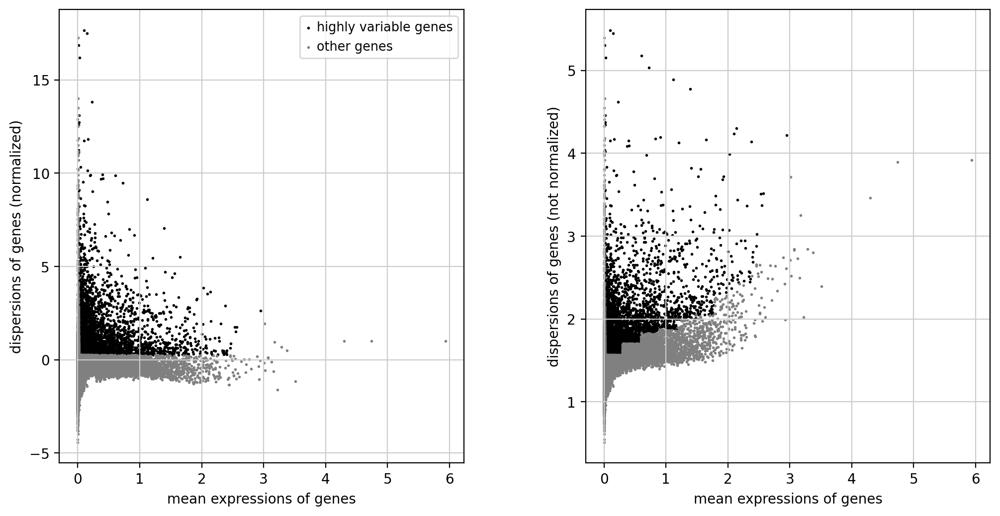

CPU times: user 11min 43s, sys: 2min 26s, total: 14min 9s
Wall time: 5min 53s


In [6]:
%%time
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.25)
sc.pl.highly_variable_genes(adata) 

In [7]:
%%time
adata = adata[:, adata.var.highly_variable].copy()

CPU times: user 1min 51s, sys: 1min 49s, total: 3min 40s
Wall time: 3min 40s


In [8]:
adata

AnnData object with n_obs × n_vars = 9697974 × 5412
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'bc1_well', 'bc2_well', 'bc3_well', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_MT', 'pct_counts_MT', 'log1p_total_counts_MT', 'donor', 'cytokine', 'treatment', 'cell_type'
    var: 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'

In [9]:
%%time
adata.write_h5ad(obj_save_path + "adata_hvg_only.h5ad")

CPU times: user 5.61 s, sys: 31.3 s, total: 36.9 s
Wall time: 40.3 s


In [10]:
adata

AnnData object with n_obs × n_vars = 9697974 × 5412
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'bc1_well', 'bc2_well', 'bc3_well', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_MT', 'pct_counts_MT', 'log1p_total_counts_MT', 'donor', 'cytokine', 'treatment', 'cell_type'
    var: 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'

In [9]:
%%time
adata = sc.read_h5ad(obj_save_path + "adata_hvg_only.h5ad")

CPU times: user 11.8 s, sys: 22.3 s, total: 34.1 s
Wall time: 34.1 s


In [10]:
adata

AnnData object with n_obs × n_vars = 9697974 × 5412
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'bc1_well', 'bc2_well', 'bc3_well', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_MT', 'pct_counts_MT', 'log1p_total_counts_MT', 'donor', 'cytokine', 'treatment', 'cell_type'
    var: 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'log1p'

In [11]:
%%time
sc.pp.scale(adata, max_value=10)

CPU times: user 5min 59s, sys: 4min 35s, total: 10min 35s
Wall time: 6min 49s


In [12]:
adata

AnnData object with n_obs × n_vars = 9697974 × 5412
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'bc1_well', 'bc2_well', 'bc3_well', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_MT', 'pct_counts_MT', 'log1p_total_counts_MT', 'donor', 'cytokine', 'treatment', 'cell_type'
    var: 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'hvg', 'log1p'

In [13]:
%%time
sc.pp.pca(adata)

CPU times: user 9h 32min 22s, sys: 4min 29s, total: 9h 36min 52s
Wall time: 25min 10s


In [14]:
adata

AnnData object with n_obs × n_vars = 9697974 × 5412
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'bc1_well', 'bc2_well', 'bc3_well', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_MT', 'pct_counts_MT', 'log1p_total_counts_MT', 'donor', 'cytokine', 'treatment', 'cell_type'
    var: 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'

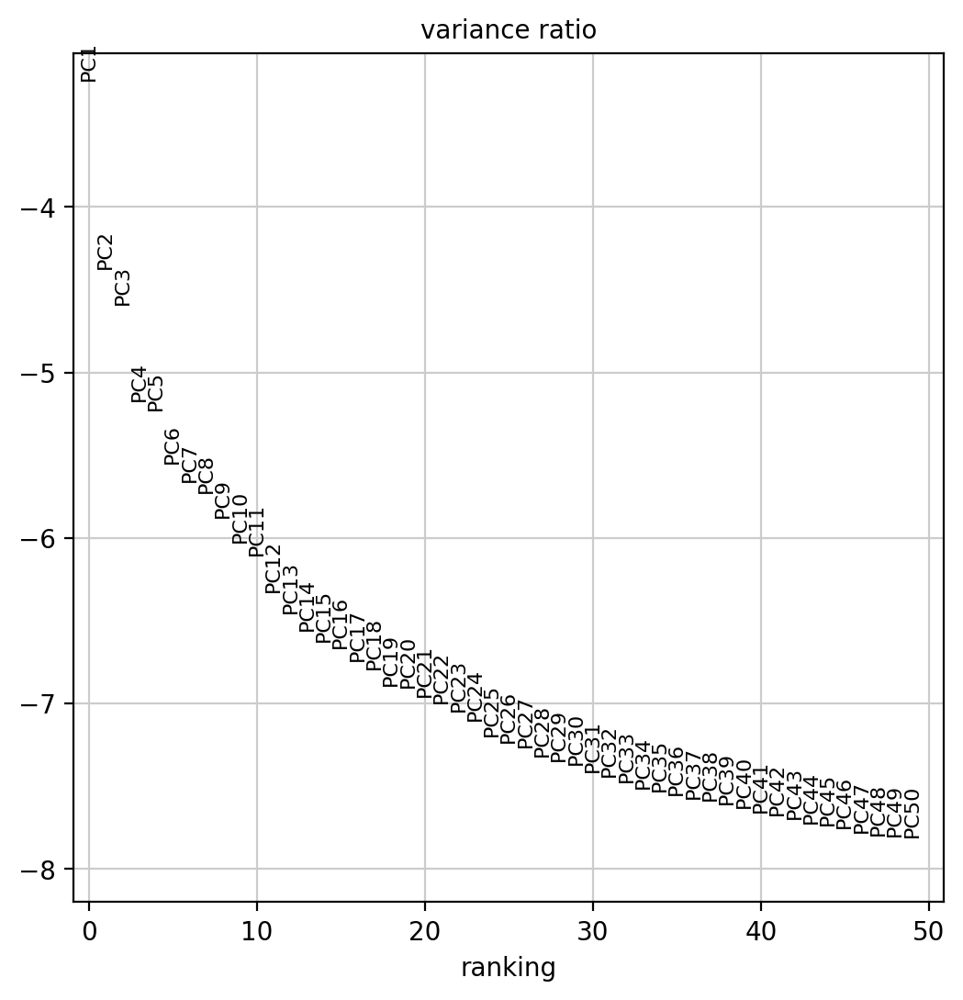

CPU times: user 168 ms, sys: 760 ms, total: 928 ms
Wall time: 923 ms


In [15]:
%%time
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

In [16]:
%%time
adata.write_h5ad(obj_save_path + "adata_pca.h5ad")

CPU times: user 2.36 s, sys: 3min 22s, total: 3min 24s
Wall time: 3min 47s


In [14]:
print("test")

test


In [15]:
%%time
adata = sc.read_h5ad(obj_save_path + "adata_pca.h5ad")

CPU times: user 8.3 s, sys: 1min 49s, total: 1min 57s
Wall time: 1min 57s


In [16]:
adata

AnnData object with n_obs × n_vars = 9697974 × 5412
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'bc1_well', 'bc2_well', 'bc3_well', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_MT', 'pct_counts_MT', 'log1p_total_counts_MT', 'donor', 'cytokine', 'treatment', 'cell_type'
    var: 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'

In [17]:
adata.obsm["X_pca"]

array([[-9.2667828e+00, -2.7804239e+00, -4.6306095e+00, ...,
         2.1610315e+00, -2.6292178e-01,  1.1162632e+00],
       [ 2.3372700e+00,  1.8889820e+01, -1.2651421e+00, ...,
         1.2209070e+00,  6.4237499e-01, -3.2682981e+00],
       [ 4.0030923e-01,  1.6212111e+01, -1.4805555e+00, ...,
         1.5114923e+00, -3.9245026e+00, -6.4224200e-03],
       ...,
       [-9.6702747e+00, -3.2503378e+00, -2.6661453e+00, ...,
        -4.2006192e-01, -2.5953293e-01, -1.2573227e-01],
       [-9.9200420e+00, -3.5246196e+00, -2.7292643e+00, ...,
         1.3139755e+00, -1.5998498e+00,  3.3230558e-01],
       [-2.3216586e+00,  2.2239111e+01,  1.7435629e-02, ...,
         7.7533615e-01,  4.5299749e-03, -1.6290570e+00]], dtype=float32)

### Continue with neighbors, umap, and leiden

In [18]:
%%time
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30)

/home/ubuntu/miniconda3/envs/spipe3/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CPU times: user 41min 33s, sys: 3min 9s, total: 44min 43s
Wall time: 42min 52s


In [19]:
adata

AnnData object with n_obs × n_vars = 9697974 × 5412
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'bc1_well', 'bc2_well', 'bc3_well', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_MT', 'pct_counts_MT', 'log1p_total_counts_MT', 'donor', 'cytokine', 'treatment', 'cell_type'
    var: 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'hvg', 'log1p', 'pca', 'neighbors'
    obsm: 'X_pca'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [20]:
%%time
sc.tl.umap(adata)

CPU times: user 4h 22min 6s, sys: 4min 14s, total: 4h 26min 20s
Wall time: 2h 22min 13s


In [21]:
adata

AnnData object with n_obs × n_vars = 9697974 × 5412
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'bc1_well', 'bc2_well', 'bc3_well', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_MT', 'pct_counts_MT', 'log1p_total_counts_MT', 'donor', 'cytokine', 'treatment', 'cell_type'
    var: 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'hvg', 'log1p', 'pca', 'neighbors', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [22]:
adata.write_h5ad(obj_save_path + 'adata_umap.h5ad')

In [23]:
%%time
sc.tl.leiden(adata, resolution=1.0, flavor="igraph", n_iterations=2, key_added="leiden_1.0")

CPU times: user 12min 47s, sys: 1min 31s, total: 14min 19s
Wall time: 14min 14s


In [24]:
adata

AnnData object with n_obs × n_vars = 9697974 × 5412
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'bc1_well', 'bc2_well', 'bc3_well', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_MT', 'pct_counts_MT', 'log1p_total_counts_MT', 'donor', 'cytokine', 'treatment', 'cell_type', 'leiden_1.0'
    var: 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'hvg', 'log1p', 'pca', 'neighbors', 'umap', 'leiden_1.0'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [25]:
%%time
adata.write_h5ad(obj_save_path + 'adata_leiden.h5ad')

CPU times: user 9.75 s, sys: 3min 24s, total: 3min 34s
Wall time: 6min 15s


#### Plotting

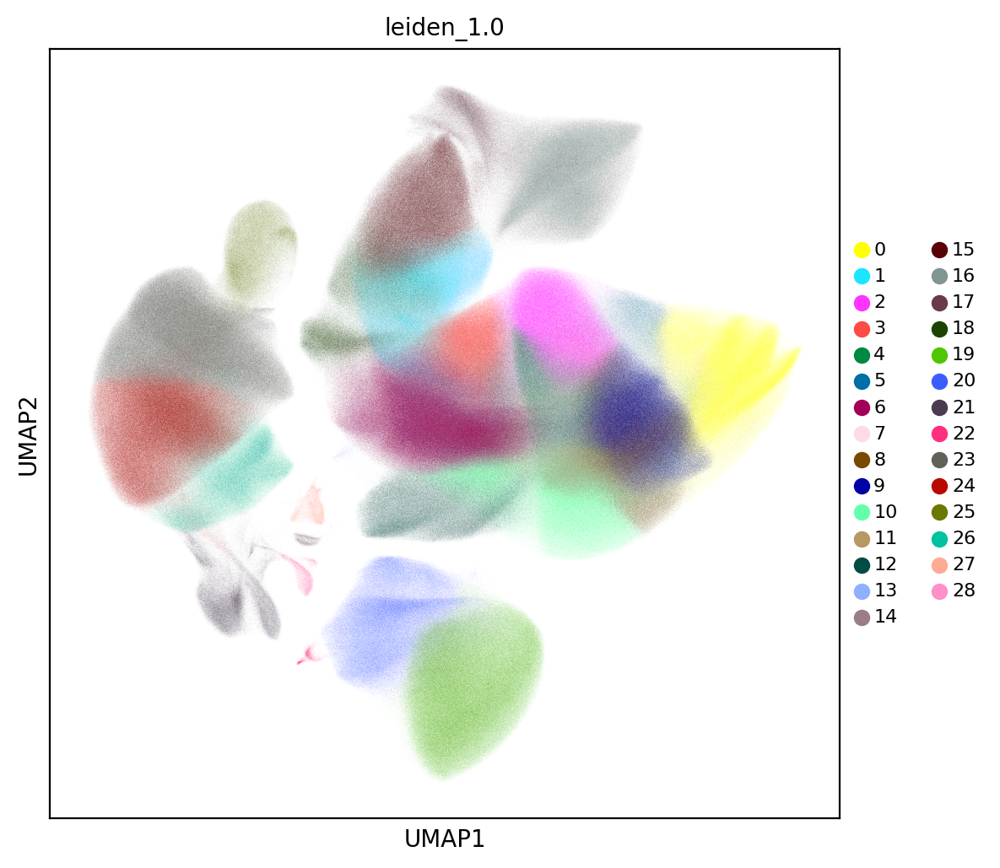

CPU times: user 24.4 s, sys: 1.49 s, total: 25.9 s
Wall time: 25.9 s


In [26]:
%%time
sc.pl.umap(adata, color='leiden_1.0', legend_fontsize=8)

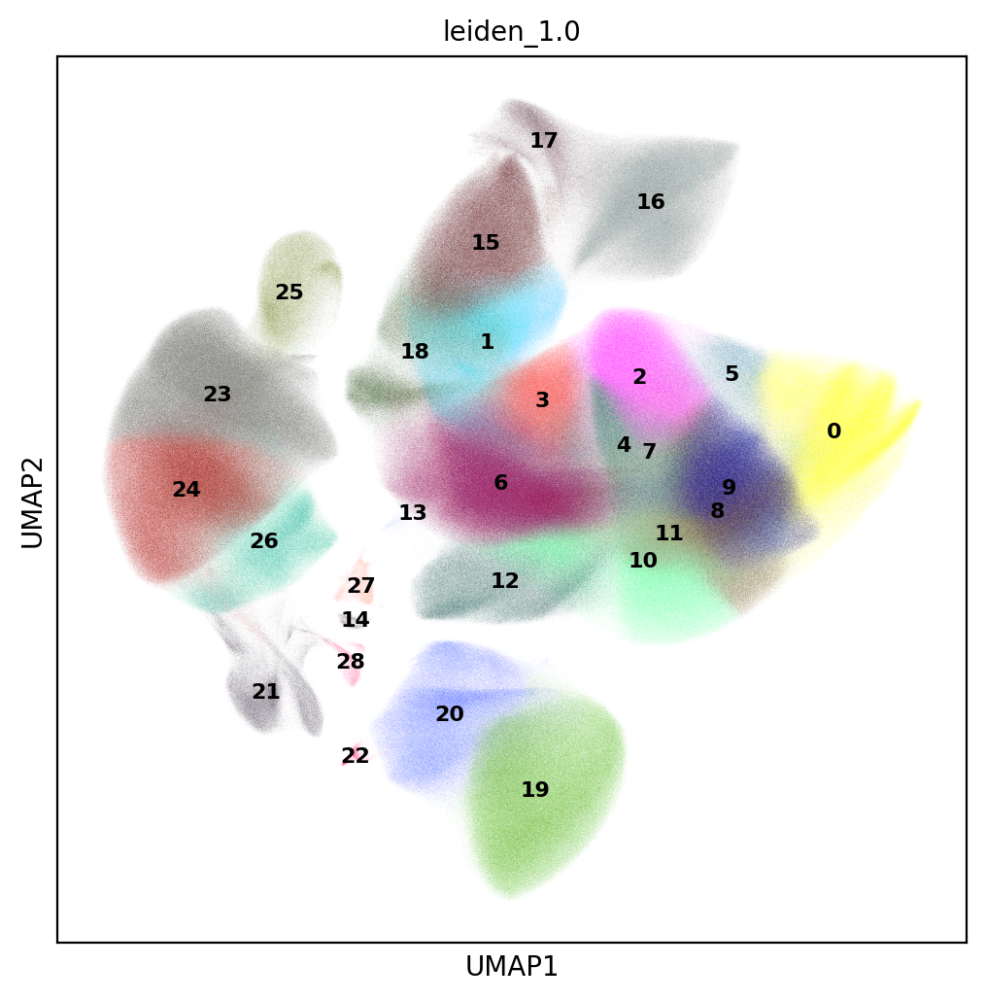

CPU times: user 24.9 s, sys: 1.24 s, total: 26.1 s
Wall time: 26.2 s


In [27]:
%%time
sc.pl.umap(adata, color='leiden_1.0', legend_fontsize=8, legend_loc = "on data")

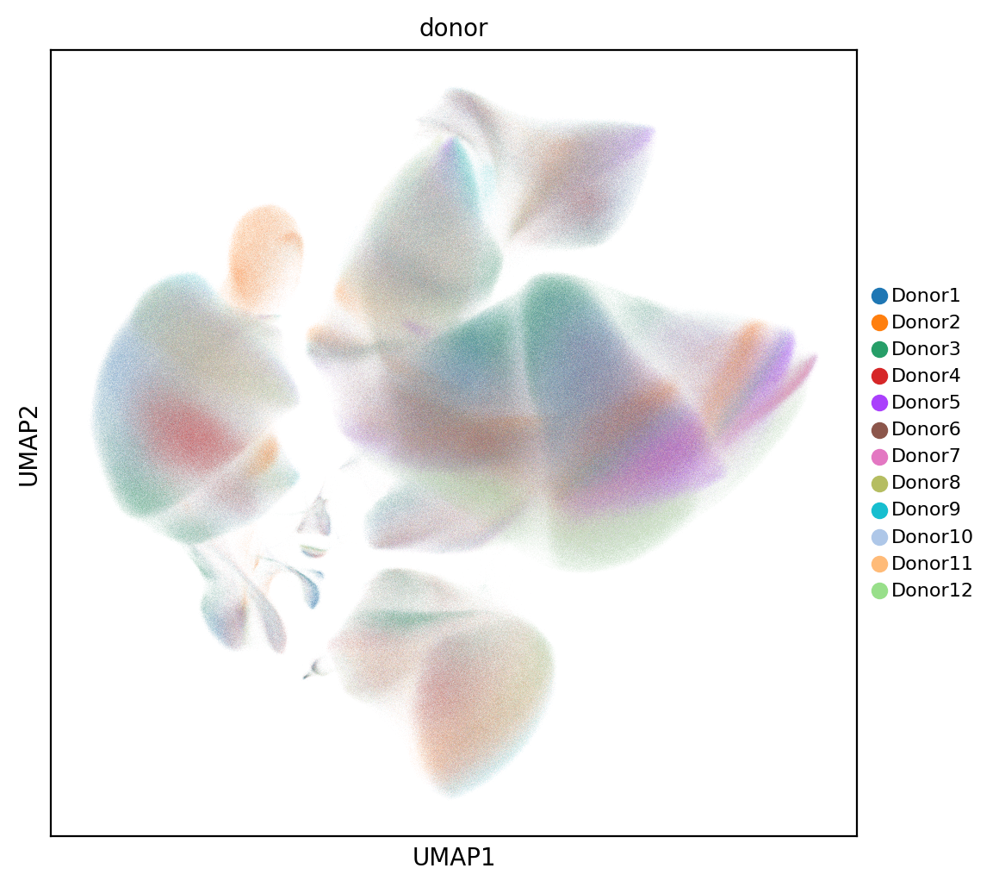

CPU times: user 24.3 s, sys: 1.2 s, total: 25.5 s
Wall time: 25.5 s


In [28]:
%%time
sc.pl.umap(adata, color='donor', legend_fontsize=8)

### Plot with cell type annotations that were determined from a previous workflow using standard PBMC markers

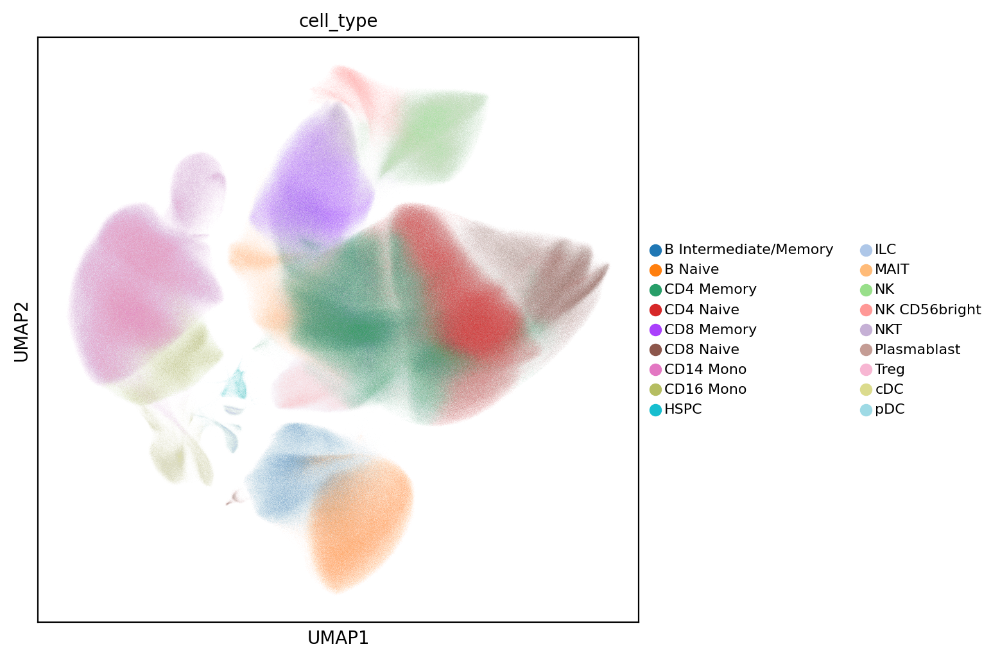

CPU times: user 24.7 s, sys: 1.24 s, total: 25.9 s
Wall time: 25.9 s


In [29]:
%%time
sc.pl.umap(adata, color='cell_type', legend_fontsize=8)

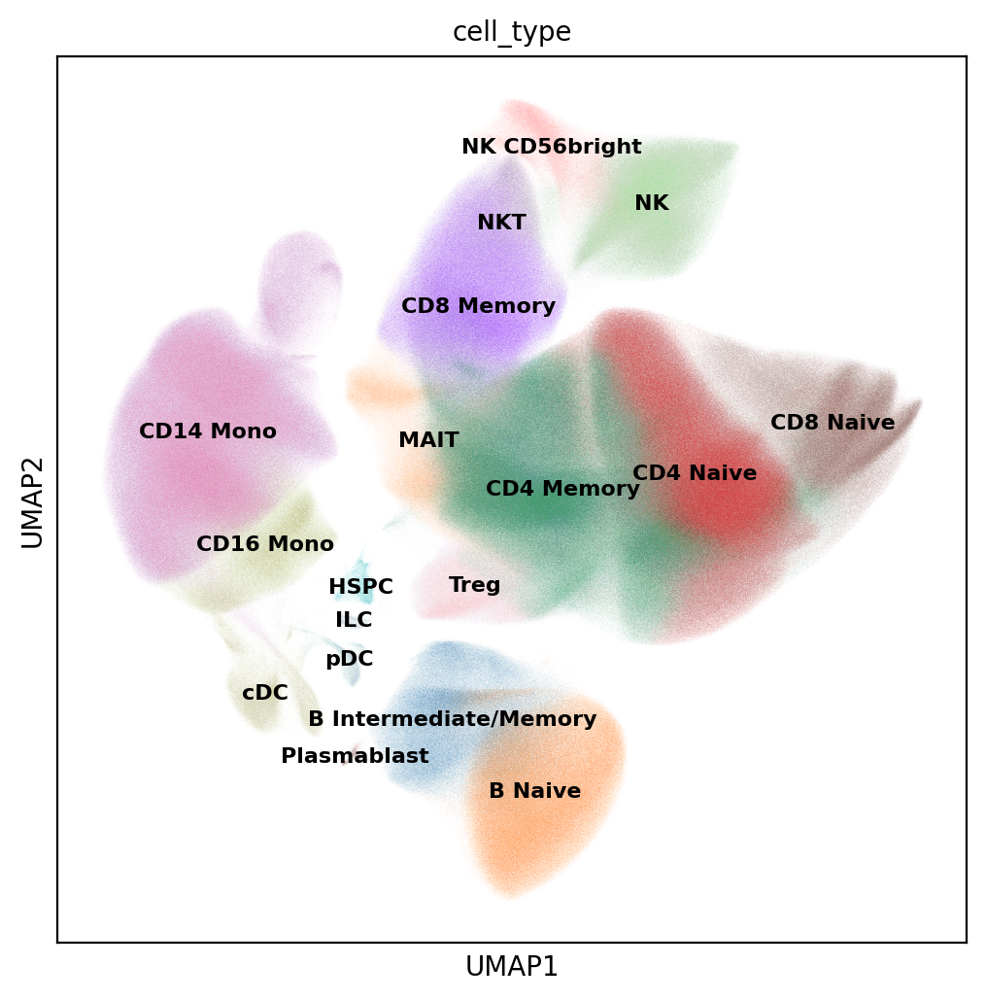

CPU times: user 25.4 s, sys: 1.22 s, total: 26.6 s
Wall time: 26.6 s


In [30]:
%%time
sc.pl.umap(adata, color='cell_type', legend_fontsize=8, legend_loc = "on data")

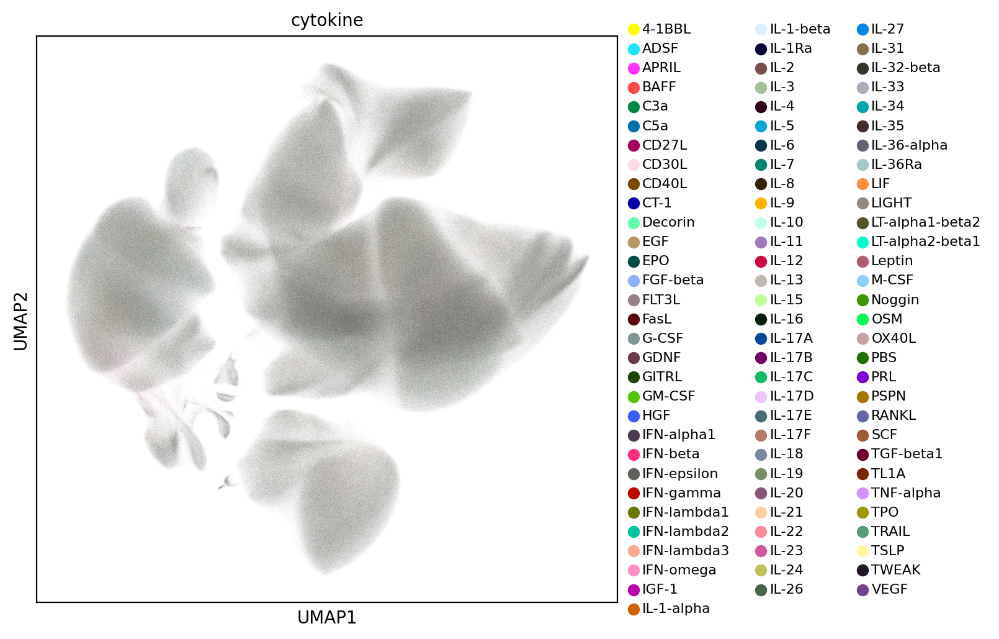

CPU times: user 25.5 s, sys: 1.16 s, total: 26.7 s
Wall time: 26.7 s


In [31]:
%%time
sc.pl.umap(adata, color='cytokine', legend_fontsize=8)

#### If it is desirable to remove the batch effects of having different PBMC donors, one can run harmony integration. Due to technical variation and differences in underlying biology between PBMC donors, integrating with harmony can help users more easily identify which clusters correspond to which cell type. 

In [32]:
%%time
sce.pp.harmony_integrate(adata, 'donor')

2024-12-14 03:55:19,647 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2024-12-14 04:01:10,550 - harmonypy - INFO - sklearn.KMeans initialization complete.
2024-12-14 04:01:36,236 - harmonypy - INFO - Iteration 1 of 10
2024-12-14 04:44:16,657 - harmonypy - INFO - Iteration 2 of 10
2024-12-14 05:26:37,391 - harmonypy - INFO - Iteration 3 of 10
2024-12-14 06:08:52,654 - harmonypy - INFO - Iteration 4 of 10
2024-12-14 06:51:05,432 - harmonypy - INFO - Iteration 5 of 10
2024-12-14 07:32:27,957 - harmonypy - INFO - Iteration 6 of 10
2024-12-14 07:46:02,779 - harmonypy - INFO - Converged after 6 iterations


CPU times: user 20h 42min 15s, sys: 52min 34s, total: 21h 34min 49s
Wall time: 3h 50min 48s


In [33]:
adata

AnnData object with n_obs × n_vars = 9697974 × 5412
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'bc1_well', 'bc2_well', 'bc3_well', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_MT', 'pct_counts_MT', 'log1p_total_counts_MT', 'donor', 'cytokine', 'treatment', 'cell_type', 'leiden_1.0'
    var: 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'hvg', 'leiden_1.0', 'log1p', 'neighbors', 'pca', 'umap', 'cell_type_colors'
    obsm: 'X_pca', 'X_umap', 'X_pca_harmony'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [34]:
%%time
adata.write_h5ad(obj_save_path + 'adata_harmony.h5ad')

CPU times: user 41.5 s, sys: 5min 22s, total: 6min 3s
Wall time: 16min 4s


#### Continue with neighbors. To use the results of harmony integration, we set use_rep = "X_pca_harmony"

In [35]:
%%time
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, use_rep="X_pca_harmony")

/home/ubuntu/miniconda3/envs/spipe3/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CPU times: user 44min 16s, sys: 1min 55s, total: 46min 11s
Wall time: 45min 35s


In [36]:
adata

AnnData object with n_obs × n_vars = 9697974 × 5412
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'bc1_well', 'bc2_well', 'bc3_well', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_MT', 'pct_counts_MT', 'log1p_total_counts_MT', 'donor', 'cytokine', 'treatment', 'cell_type', 'leiden_1.0'
    var: 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'hvg', 'leiden_1.0', 'log1p', 'neighbors', 'pca', 'umap', 'cell_type_colors'
    obsm: 'X_pca', 'X_umap', 'X_pca_harmony'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

#### Continue with umap and leiden clustering.

In [37]:
%%time
sc.tl.umap(adata)

CPU times: user 4h 15min 12s, sys: 4min 33s, total: 4h 19min 46s
Wall time: 2h 27min 2s


In [38]:
adata

AnnData object with n_obs × n_vars = 9697974 × 5412
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'bc1_well', 'bc2_well', 'bc3_well', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_MT', 'pct_counts_MT', 'log1p_total_counts_MT', 'donor', 'cytokine', 'treatment', 'cell_type', 'leiden_1.0'
    var: 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'hvg', 'leiden_1.0', 'log1p', 'neighbors', 'pca', 'umap', 'cell_type_colors'
    obsm: 'X_pca', 'X_umap', 'X_pca_harmony'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [39]:
%%time
adata.write_h5ad(obj_save_path + 'adata_harmony_umap.h5ad')

CPU times: user 55.5 s, sys: 4min 35s, total: 5min 31s
Wall time: 17min 10s


In [40]:
%%time
#run leiden with a few resolutions to help with cell type annotations
sc.tl.leiden(adata, resolution=1.0, flavor="igraph", n_iterations=2, key_added="leiden_1.0")
sc.tl.leiden(adata, resolution=1.4, flavor="igraph", n_iterations=2, key_added="leiden_1.4")
sc.tl.leiden(adata, resolution=1.8, flavor="igraph", n_iterations=2, key_added="leiden_1.8")

CPU times: user 41min 36s, sys: 7min 38s, total: 49min 15s
Wall time: 48min 44s


In [41]:
adata

AnnData object with n_obs × n_vars = 9697974 × 5412
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'bc1_well', 'bc2_well', 'bc3_well', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_MT', 'pct_counts_MT', 'log1p_total_counts_MT', 'donor', 'cytokine', 'treatment', 'cell_type', 'leiden_1.0', 'leiden_1.4', 'leiden_1.8'
    var: 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'hvg', 'leiden_1.0', 'log1p', 'neighbors', 'pca', 'umap', 'cell_type_colors', 'leiden_1.4', 'leiden_1.8'
    obsm: 'X_pca', 'X_umap', 'X_pca_harmony'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [42]:
%%time
adata.write_h5ad(obj_save_path + 'adata_harmony_leiden.h5ad')

CPU times: user 48.8 s, sys: 3min 52s, total: 4min 41s
Wall time: 16min 59s


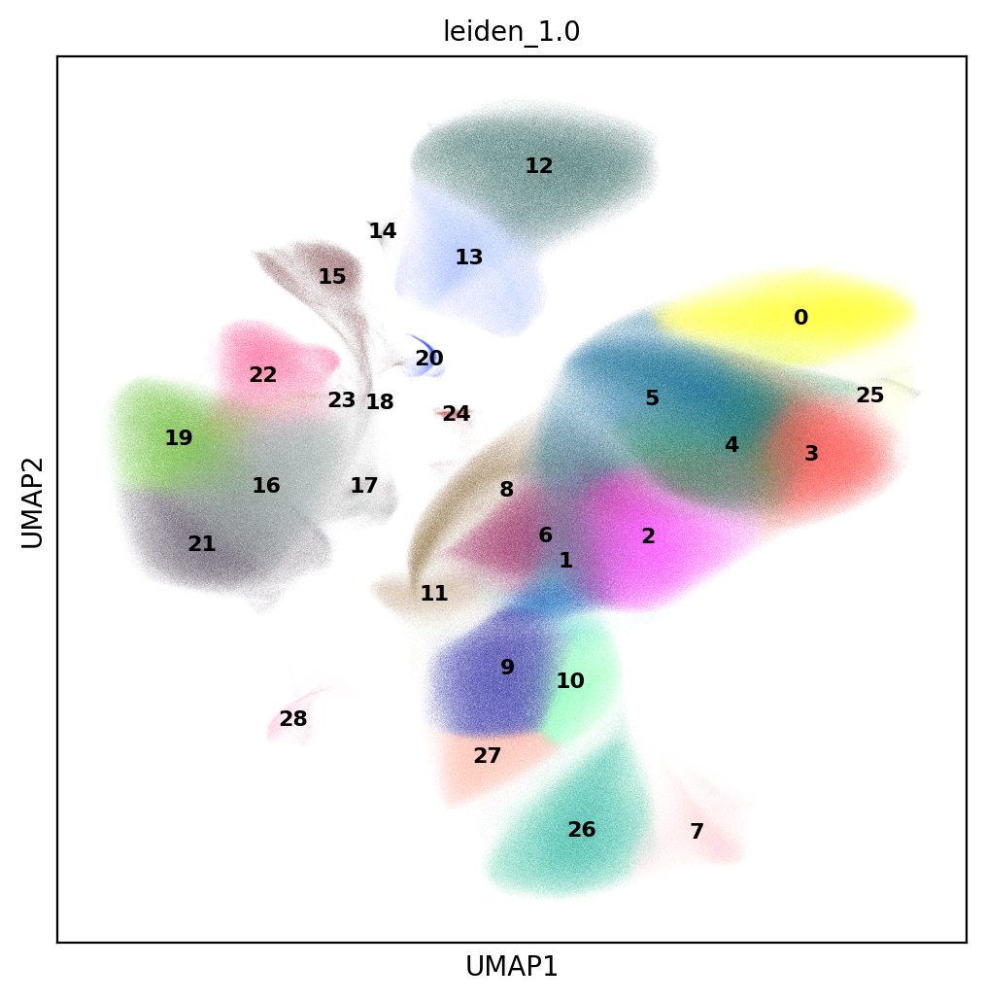

CPU times: user 24.9 s, sys: 1.46 s, total: 26.4 s
Wall time: 26.4 s


In [43]:
%%time
sc.pl.umap(adata, color='leiden_1.0', legend_fontsize=8, legend_loc = "on data")

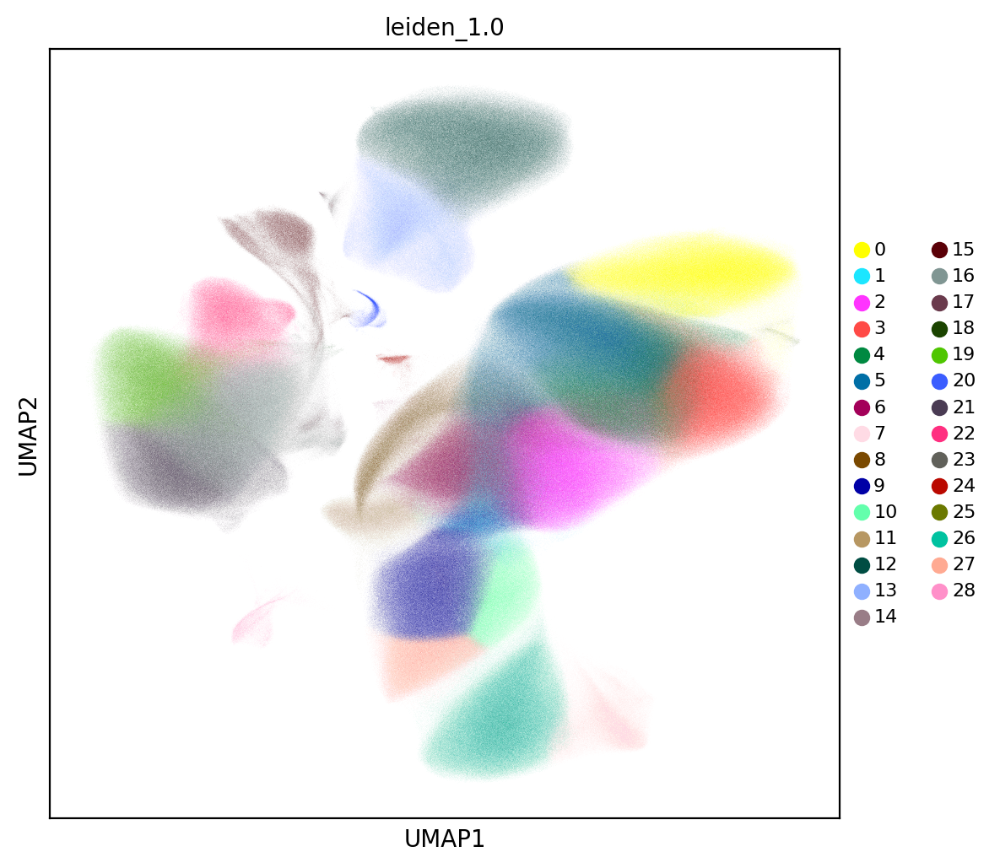

CPU times: user 25 s, sys: 1.23 s, total: 26.2 s
Wall time: 26.2 s


In [44]:
%%time
sc.pl.umap(adata, color='leiden_1.0', legend_fontsize=8)

#### We now plot by donor to show the results of harmony integration. 

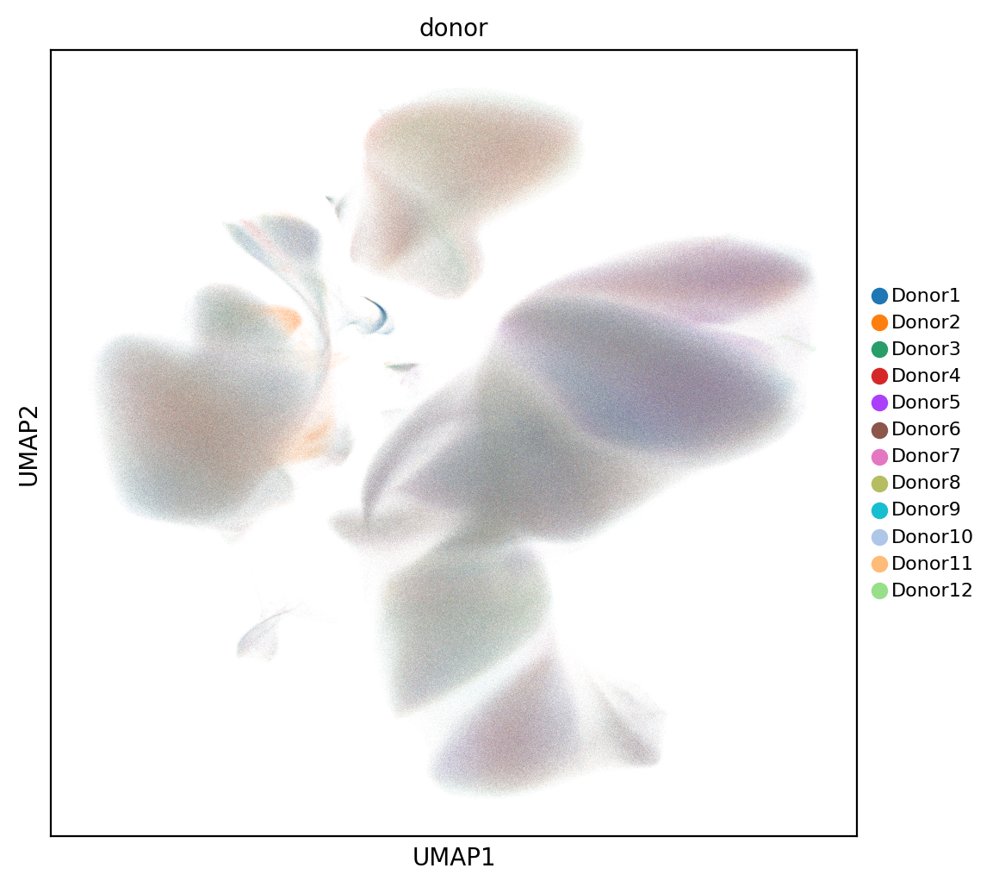

CPU times: user 24.7 s, sys: 1.13 s, total: 25.8 s
Wall time: 25.8 s


In [45]:
%%time
sc.pl.umap(adata, color='donor', legend_fontsize=8)

#### The first and most notable effect of running the integration function to is seeing how the samples overlap with another, which simplifies the process of annotating cell types as it reduces the number of clusters. In this case, we don't see a drastic reduction in numbers of clusters, but in scenarios where we see greater technical and biological variation, this can have a much greater impact. 

#### We now overlay cell type annotations on the umap plot, which were determined from a previous workflow using standard marker genes for PBMCs.

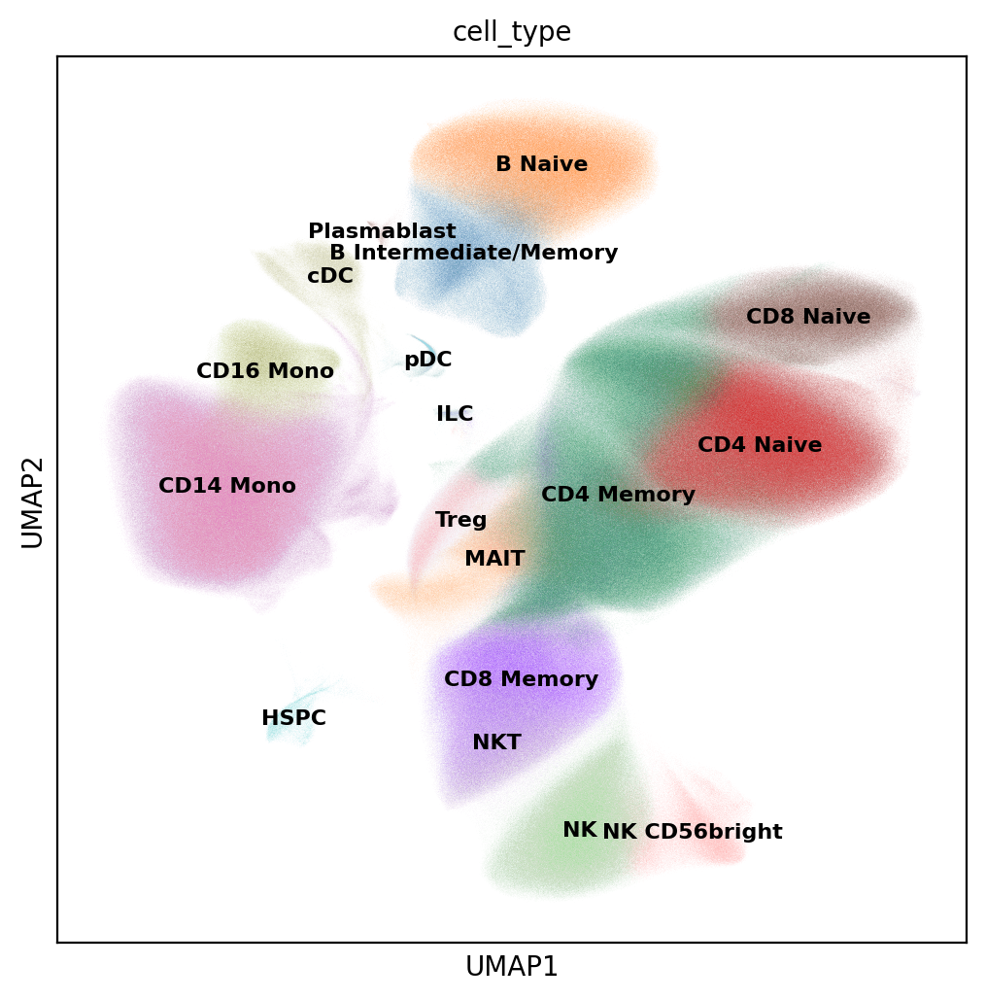

CPU times: user 24.9 s, sys: 1.38 s, total: 26.3 s
Wall time: 26.3 s


In [46]:
%%time
sc.pl.umap(adata, color='cell_type', legend_fontsize=8, legend_loc = "on data")

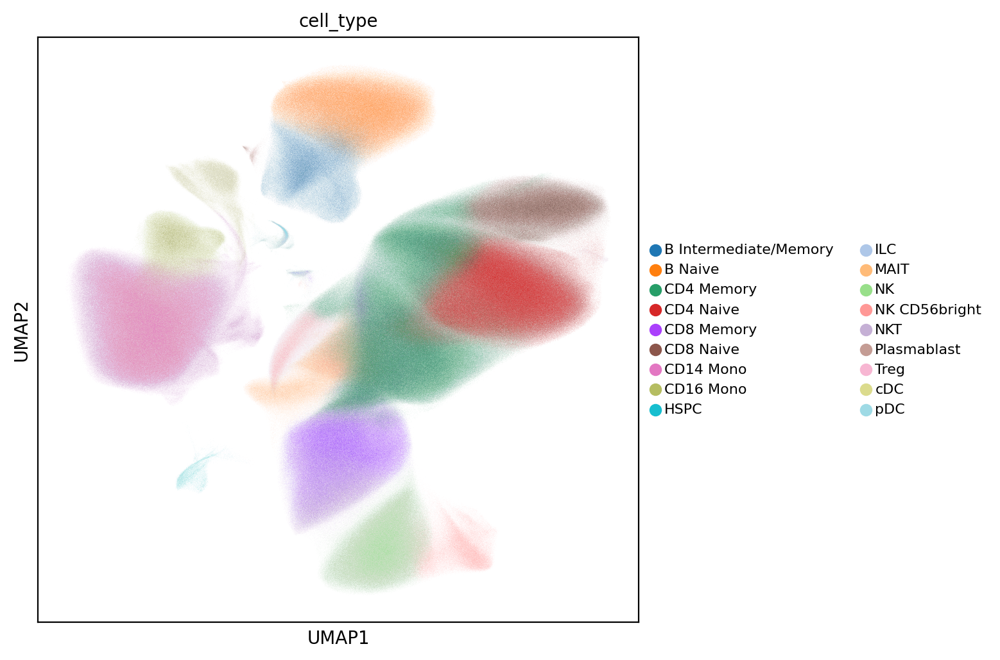

CPU times: user 24.7 s, sys: 1.25 s, total: 26 s
Wall time: 26 s


In [47]:
%%time
sc.pl.umap(adata, color='cell_type', legend_fontsize=8)

#### We can also plot the cytokines 

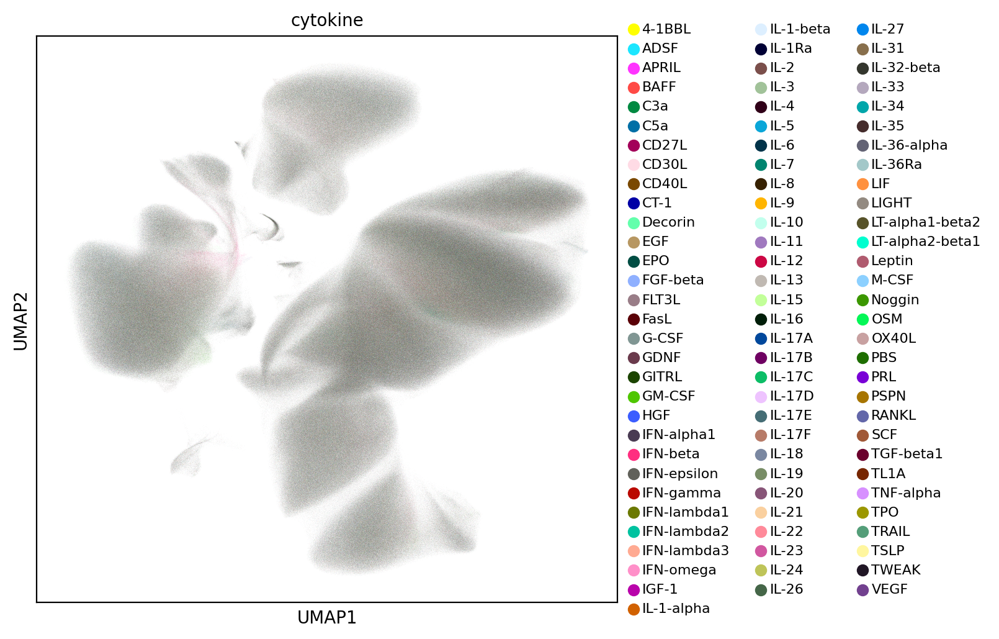

CPU times: user 26 s, sys: 1.83 s, total: 27.9 s
Wall time: 27.8 s


In [48]:
%%time
sc.pl.umap(adata, color='cytokine', legend_fontsize=8)